## Task 1: Real-World Data Ingestion & Validation
Load and validate the genuine agroclimatology and historical crop yield dataset (2001–2022) across Punjab, Sindh, and Balochistan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", 30)
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
print(f"Project root: {PROJECT_ROOT}")

data_path = PROJECT_ROOT / "data/raw/pakistan_crop_yield_climate.parquet"
if not data_path.exists():
    data_path = PROJECT_ROOT / "data/raw/pakistan_crop_yield_climate.csv"

df = pd.read_parquet(data_path) if data_path.suffix == ".parquet" else pd.read_csv(data_path)
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns")

Project root: /home/prx/Projects/machine-learning/climate-machine-learning
Loaded dataset: 10,296 rows, 19 columns


In [3]:
assert df.shape == (10296, 19), f"Unexpected shape: {df.shape}"
print("Shape assertion passed: 10,296 rows, 19 columns.")
print()
print("Dataset Columns and Types:")
print(df.dtypes)

Shape assertion passed: 10,296 rows, 19 columns.

Dataset Columns and Types:
Year                                   int64
Crop                                     str
Area                                 float64
Production                           float64
Yield                                float64
Province                                 str
temperature_2m_max                   float64
temperature_2m_min                   float64
temperature_2m_mean                  float64
Combined_temperature_normalized      float64
precipitation_sum                    float64
precipitation_sum_normalized         float64
shortwave_radiation                  float64
shortwave_radiation_normalized       float64
fao_evapotranspiration               float64
fao_evapotranspiration_normalized    float64
precipitation_hours                    int64
precipitation_hours_normalized       float64
Climate_Index                        float64
dtype: object


In [4]:
missing_counts = df.isnull().sum()
print("Missing values per column:")
print(missing_counts[missing_counts > 0] if (missing_counts > 0).any() else "No missing values found across all columns.")
assert missing_counts.sum() == 0, "Missing values detected in raw data!"

Missing values per column:
No missing values found across all columns.


In [5]:
crop_stats = df.groupby("Crop").agg(
    Observations=("Yield", "count"),
    Min_Yield=("Yield", "min"),
    Max_Yield=("Yield", "max"),
    Mean_Yield=("Yield", "mean"),
    Std_Yield=("Yield", "std"),
    Mean_Precipitation=("precipitation_sum", "mean"),
    Mean_Evapotranspiration=("fao_evapotranspiration", "mean"),
).reset_index().sort_values("Mean_Yield")

print("Crop Yield & Climate Statistics (Real Historical Variance):")
print(crop_stats.to_string(index=False))

DROUGHT_RESILIENT_CROPS = ["dates", "grapes", "pomegranate", "wheat", "onion"]
WATER_INTENSIVE_CROPS = ["sugarcane", "rice", "banana", "cotton"]

df["Is_Drought_Resilient"] = df["Crop"].isin(DROUGHT_RESILIENT_CROPS)
print()
print(f"Drought-resilient / lower-water crops: {DROUGHT_RESILIENT_CROPS}")
print(f"Water-intensive crops: {WATER_INTENSIVE_CROPS}")


Crop Yield & Climate Statistics (Real Historical Variance):
       Crop  Observations  Min_Yield  Max_Yield  Mean_Yield  Std_Yield  Mean_Precipitation  Mean_Evapotranspiration
     cotton           792       2.83      15.65    6.677879   2.494245           21.346338                 5.502689
     grapes           792       0.00      68.54   15.357727  21.285229           21.346338                 5.502689
       rice           792       6.91      38.26   26.896818   7.527966           21.346338                 5.502689
      wheat           792      14.76      37.91   27.609697   5.354806           21.346338                 5.502689
pomegranate           792       0.00     178.73   42.267879  37.349077           21.346338                 5.502689
      apple           792       0.00     105.71   43.437727  38.688787           21.346338                 5.502689
      dates           792      34.32     126.80   69.174848  21.799347           21.346338                 5.502689
     banana 

---
## Task 2: Exploratory Data Analysis (EDA)
Fulfilling the CT-378 rubric requirement of at least 5 analytical visualizations on real agroclimatology data:
1. **Yield Distribution Across All 13 Crops** (highlighting low-water/drought-resilient vs. water-intensive crops)
2. **Crop Yield vs. Precipitation & Integrated Climate Index** (assessing drought sensitivity across key crops)
3. **Provincial Climate Disparity** (temperature and FAO evapotranspiration across Punjab, Sindh, and Balochistan)
4. **Agroclimatology Correlation Heatmap** (relationships between climate drivers, area, and yield)
5. **Historical Annual Yield Volatility (2001–2022)** (demonstrating genuine historical shocks and trend dynamics)

In [6]:
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
print("Plot styling configured.")

Plot styling configured.


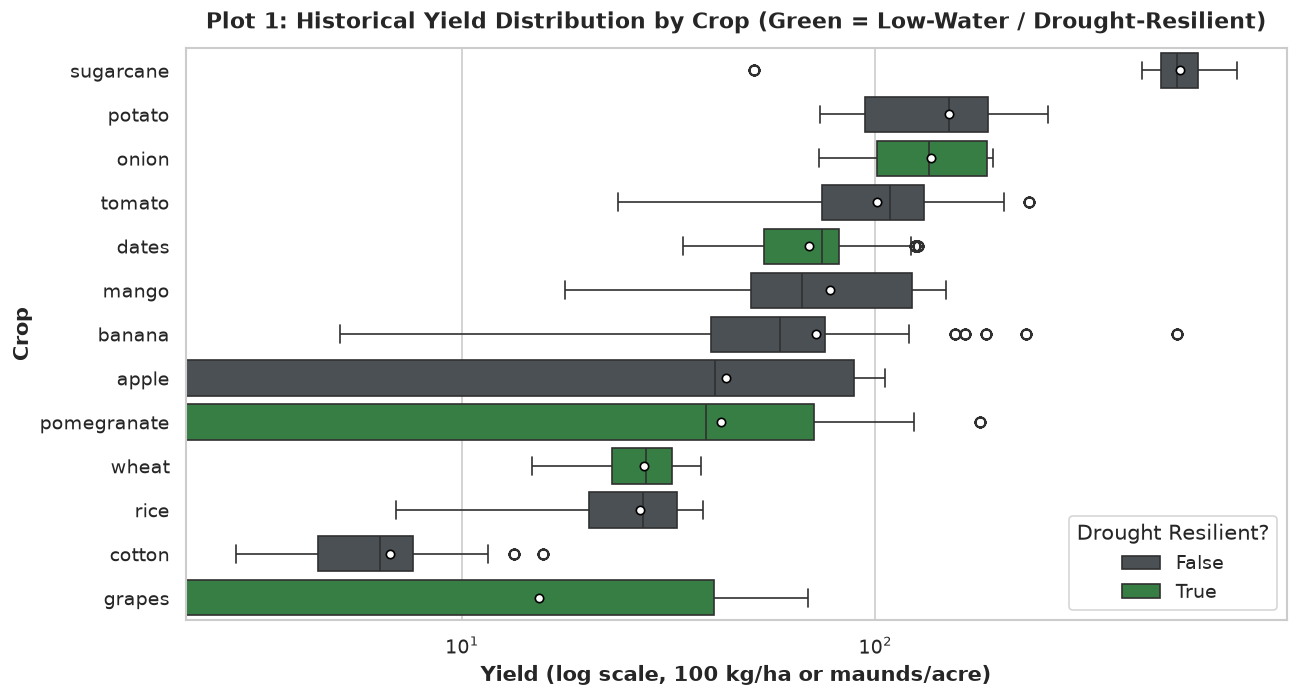

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
order = df.groupby("Crop")["Yield"].median().sort_values(ascending=False).index
palette = {True: "#2b8a3e", False: "#495057"}

sns.boxplot(
    data=df, x="Yield", y="Crop", order=order,
    hue="Is_Drought_Resilient", palette=palette, dodge=False, showmeans=True,
    meanprops={"marker":"o", "markerfacecolor":"white", "markeredgecolor":"black", "markersize":"5"},
    ax=ax
)
ax.set_xscale("log")
ax.set_title("Plot 1: Historical Yield Distribution by Crop (Green = Low-Water / Drought-Resilient)", fontsize=13, weight="bold", pad=12)
ax.set_xlabel("Yield (log scale, 100 kg/ha or maunds/acre)", weight="bold")
ax.set_ylabel("Crop", weight="bold")
ax.legend(title="Drought Resilient?", loc="lower right", frameon=True)
plt.tight_layout()
plt.show()

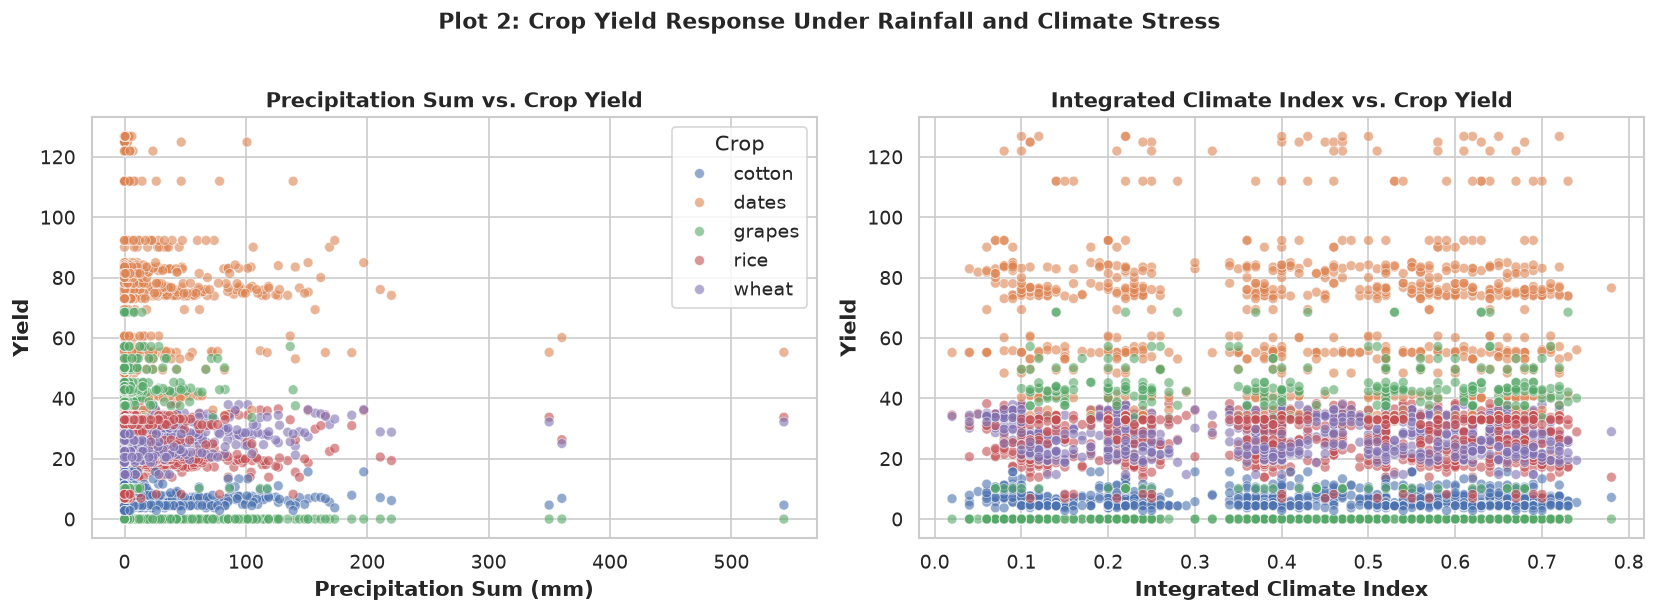

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
key_crops = ["wheat", "rice", "cotton", "dates", "grapes"]
df_sub = df[df["Crop"].isin(key_crops)]

sns.scatterplot(data=df_sub, x="precipitation_sum", y="Yield", hue="Crop", alpha=0.6, s=35, ax=ax1)
ax1.set_title("Precipitation Sum vs. Crop Yield", weight="bold")
ax1.set_xlabel("Precipitation Sum (mm)", weight="bold")
ax1.set_ylabel("Yield", weight="bold")

sns.scatterplot(data=df_sub, x="Climate_Index", y="Yield", hue="Crop", alpha=0.6, s=35, legend=False, ax=ax2)
ax2.set_title("Integrated Climate Index vs. Crop Yield", weight="bold")
ax2.set_xlabel("Integrated Climate Index", weight="bold")
ax2.set_ylabel("Yield", weight="bold")

plt.suptitle("Plot 2: Crop Yield Response Under Rainfall and Climate Stress", fontsize=13, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

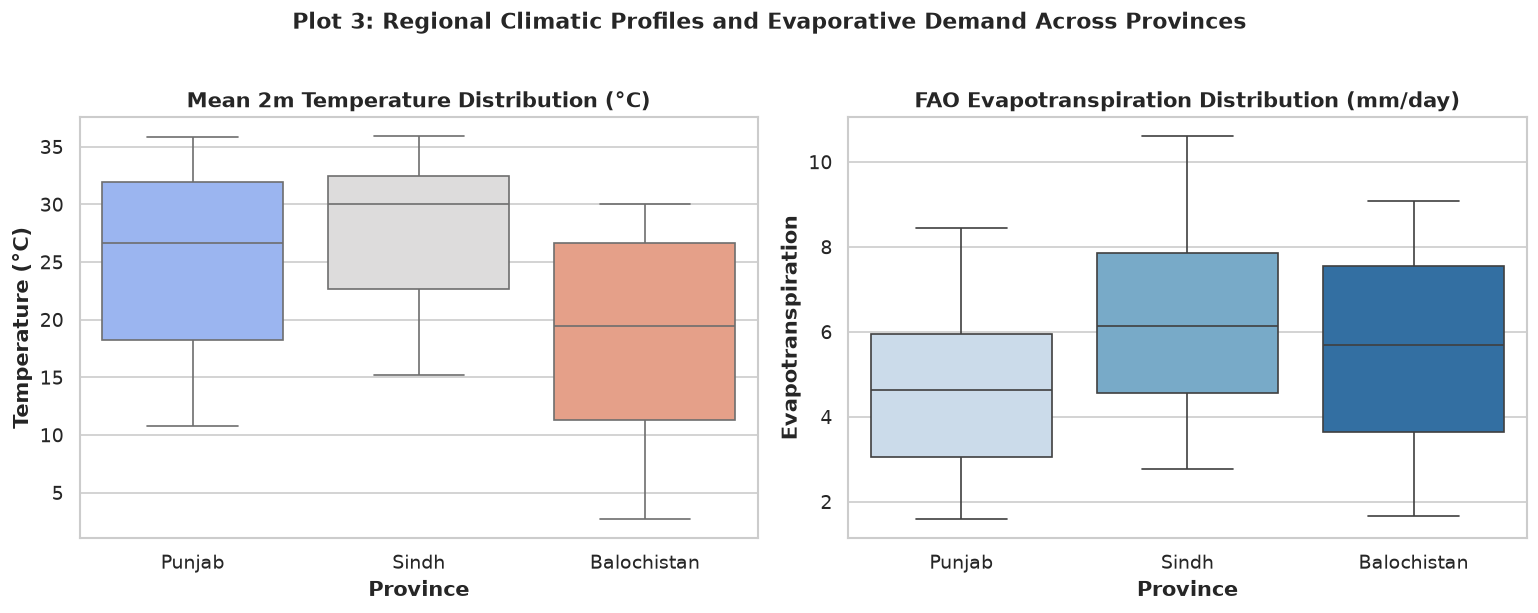

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x="Province", y="temperature_2m_mean", hue="Province", palette="coolwarm", legend=False, ax=ax1)
ax1.set_title("Mean 2m Temperature Distribution (°C)", weight="bold")
ax1.set_xlabel("Province", weight="bold")
ax1.set_ylabel("Temperature (°C)", weight="bold")

sns.boxplot(data=df, x="Province", y="fao_evapotranspiration", hue="Province", palette="Blues", legend=False, ax=ax2)
ax2.set_title("FAO Evapotranspiration Distribution (mm/day)", weight="bold")
ax2.set_xlabel("Province", weight="bold")
ax2.set_ylabel("Evapotranspiration", weight="bold")

plt.suptitle("Plot 3: Regional Climatic Profiles and Evaporative Demand Across Provinces", fontsize=13, weight="bold", y=1.02)
plt.tight_layout()
plt.show()

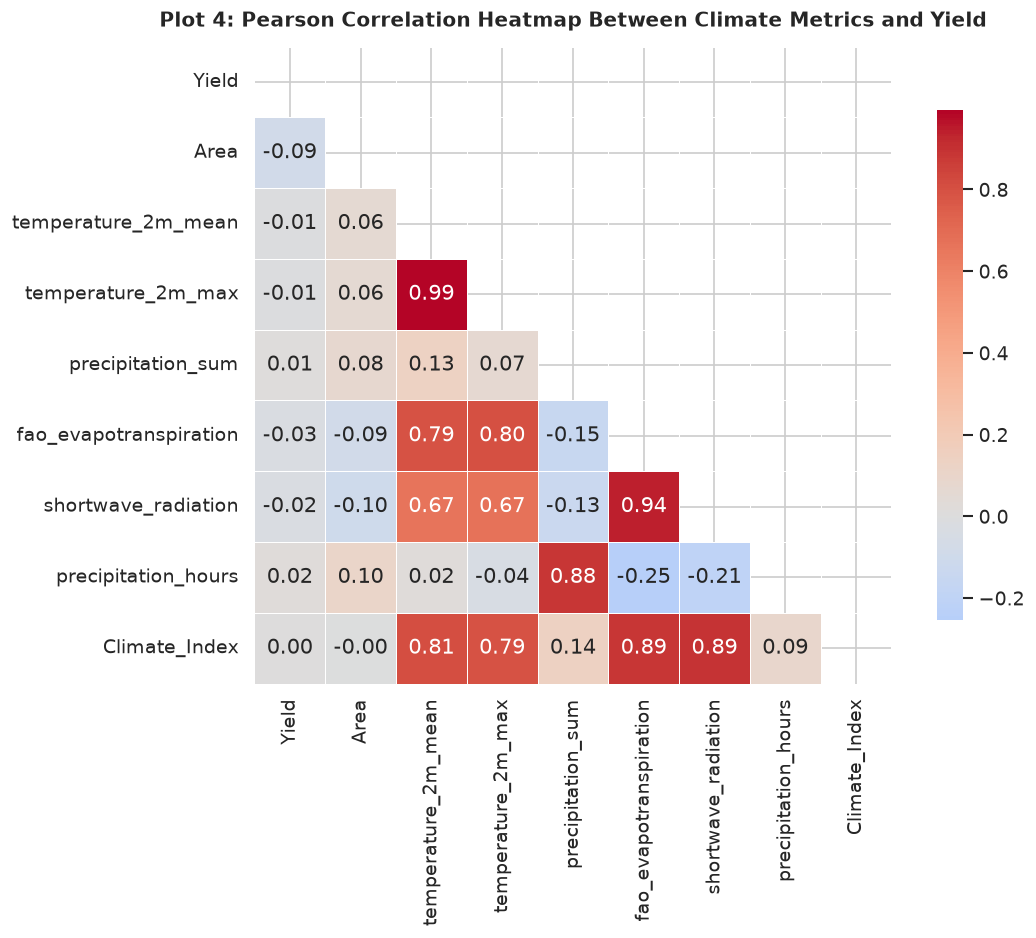

In [10]:
fig, ax = plt.subplots(figsize=(10, 8))
corr_cols = [
    "Yield", "Area", "temperature_2m_mean", "temperature_2m_max",
    "precipitation_sum", "fao_evapotranspiration", "shortwave_radiation",
    "precipitation_hours", "Climate_Index"
]
corr_matrix = df[corr_cols].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
    center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
)
plt.title("Plot 4: Pearson Correlation Heatmap Between Climate Metrics and Yield", fontsize=12, weight="bold", pad=12)
plt.tight_layout()
plt.show()

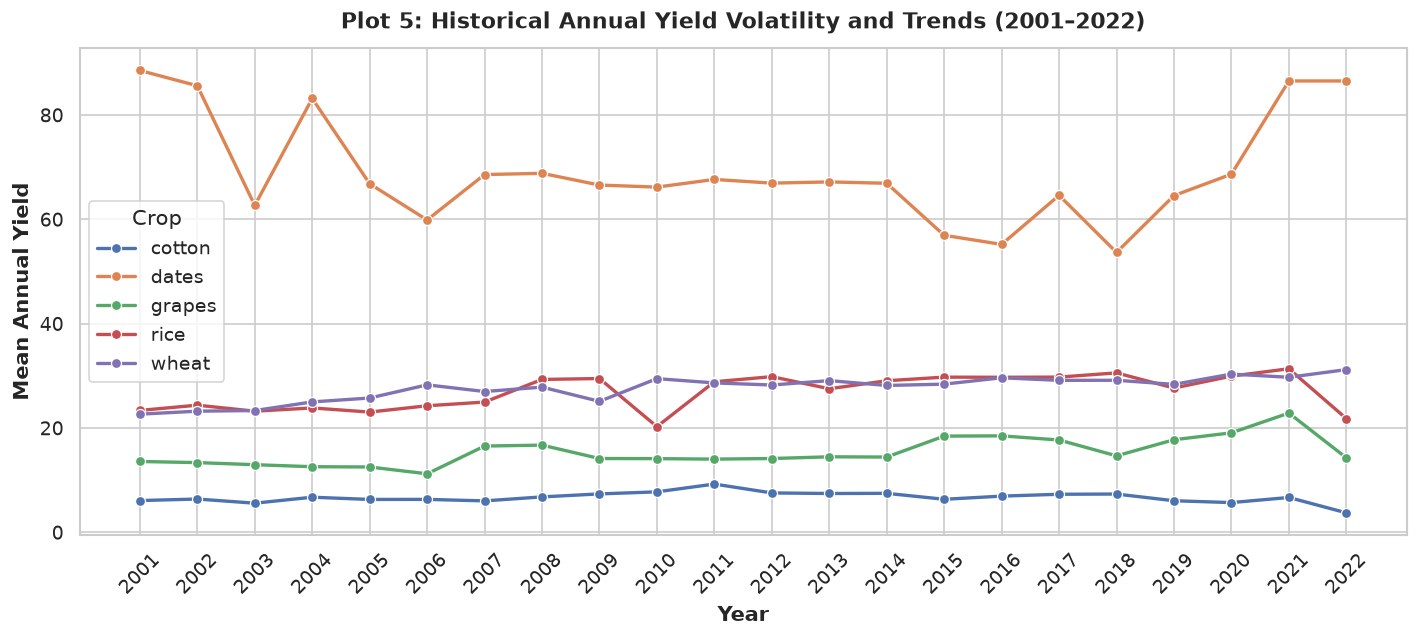

In [11]:
fig, ax = plt.subplots(figsize=(12, 5.5))
trend_crops = ["wheat", "rice", "cotton", "dates", "grapes"]
df_annual = df[df["Crop"].isin(trend_crops)].groupby(["Year", "Crop"])["Yield"].mean().reset_index()

sns.lineplot(data=df_annual, x="Year", y="Yield", hue="Crop", marker="o", linewidth=2, ax=ax)
ax.set_title("Plot 5: Historical Annual Yield Volatility and Trends (2001–2022)", fontsize=13, weight="bold", pad=12)
ax.set_xlabel("Year", weight="bold")
ax.set_ylabel("Mean Annual Yield", weight="bold")
ax.set_xticks(sorted(df["Year"].unique()))
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

---
## Task 3: Time-Ordered Train/Val/Test Split & Scikit-Learn Preprocessing Pipeline

### 1. Leak-Free Time-Ordered Split
Because agricultural yield data has temporal dependencies (climate change trends, technological advancements),
a random split would leak future weather information into past training instances.
We split strictly by `Year`:
- **Train (72.7%)**: 2001–2016 (7,488 observations)
- **Validation (13.6%)**: 2017–2019 (1,404 observations)
- **Test (13.6%)**: 2020–2022 (1,404 observations)

> **Critical Leakage Prevention:** The `Production` column is deliberately excluded from features because Yield = Production / Area. Including it would allow trivial arithmetic division rather than learning genuine climate-yield relationships.

In [12]:
num_cols = [
    "Area",
    "temperature_2m_max", "temperature_2m_min", "temperature_2m_mean",
    "Combined_temperature_normalized", "precipitation_sum", "precipitation_sum_normalized",
    "shortwave_radiation", "shortwave_radiation_normalized", "fao_evapotranspiration",
    "fao_evapotranspiration_normalized", "precipitation_hours", "precipitation_hours_normalized",
    "Climate_Index"
]

cat_cols = ["Crop", "Province", "Is_Drought_Resilient"]
target_col = "Yield"
feature_cols = num_cols + cat_cols

train_mask = df["Year"] <= 2016
val_mask = (df["Year"] >= 2017) & (df["Year"] <= 2019)
test_mask = df["Year"] >= 2020

X_train, y_train = df.loc[train_mask, feature_cols], df.loc[train_mask, target_col]
X_val, y_val = df.loc[val_mask, feature_cols], df.loc[val_mask, target_col]
X_test, y_test = df.loc[test_mask, feature_cols], df.loc[test_mask, target_col]

print(f"Training set:   {X_train.shape[0]:,} rows ({X_train.shape[0]/len(df):.1%})")
print(f"Validation set: {X_val.shape[0]:,} rows ({X_val.shape[0]/len(df):.1%})")
print(f"Test set:       {X_test.shape[0]:,} rows ({X_test.shape[0]/len(df):.1%})")
assert len(X_train) + len(X_val) + len(X_test) == len(df), "Split row count mismatch!"
print("Row partition integrity verified: exactly 10,296 records.")

Training set:   7,488 rows (72.7%)
Validation set: 1,404 rows (13.6%)
Test set:       1,404 rows (13.6%)
Row partition integrity verified: exactly 10,296 records.


### 2. Preprocessing ColumnTransformer
We construct an end-to-end ColumnTransformer:
- **Numerical Pipeline**: SimpleImputer(strategy="median") followed by StandardScaler()
- **Categorical Pipeline**: SimpleImputer(strategy="most_frequent") followed by OneHotEncoder(handle_unknown="ignore")

All transformations are fitted strictly on `X_train` to eliminate data leakage across temporal boundaries.

In [13]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols)
    ]
)

preprocessor.fit(X_train)
X_train_transformed = preprocessor.transform(X_train)
X_val_transformed = preprocessor.transform(X_val)
X_test_transformed = preprocessor.transform(X_test)

print(f"Original features: {len(feature_cols)}")
print(f"Transformed feature matrix width: {X_train_transformed.shape[1]}")
print("Preprocessing pipeline fitted and verified on training data.")

Original features: 17
Transformed feature matrix width: 32
Preprocessing pipeline fitted and verified on training data.


---
## Task 4: Baseline + 3 Model Training (Dummy, Ridge, Random Forest, HistGradientBoosting)

We train four candidate models following the CT-378 rubric:
1. **Baseline**: `DummyRegressor(strategy="mean")` (Predicts historical mean yield across crops).
2. **Linear Regularized Model**: `Ridge(alpha=10.0)`
3. **Bagging Ensemble**: `RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42)`
4. **Boosting Ensemble**: `HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=42)`

Each candidate model is combined with `preprocessor` into a complete scikit-learn `Pipeline`, trained strictly on `X_train`, and evaluated on `X_val`.

In [14]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
import time

candidate_models = {
    "Baseline (Dummy Mean)": DummyRegressor(strategy="mean"),
    "Ridge Regression": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=150, learning_rate=0.08, random_state=42)
}

val_results = []
trained_pipelines = {}

for name, estimator in candidate_models.items():
    t0 = time.time()
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("regressor", estimator)
    ])
    pipeline.fit(X_train, y_train)
    train_time = time.time() - t0
    
    preds = pipeline.predict(X_val)
    mae = mean_absolute_error(y_val, preds)
    rmse = root_mean_squared_error(y_val, preds)
    r2 = r2_score(y_val, preds)
    
    val_results.append({
        "Model": name,
        "Val MAE": round(mae, 2),
        "Val RMSE": round(rmse, 2),
        "Val R2": round(r2, 4),
        "Train Time (s)": round(train_time, 2)
    })
    trained_pipelines[name] = pipeline

df_val_results = pd.DataFrame(val_results)
print("Validation Performance Comparison Table (Real Data):")
print(df_val_results.to_string(index=False))


Validation Performance Comparison Table (Real Data):
                Model  Val MAE  Val RMSE  Val R2  Train Time (s)
Baseline (Dummy Mean)    88.81    147.23 -0.0019            0.02
     Ridge Regression    34.04     60.43  0.8312            0.02
        Random Forest    18.84     52.36  0.8733            0.46
 HistGradientBoosting    19.39     53.65  0.8670            0.26


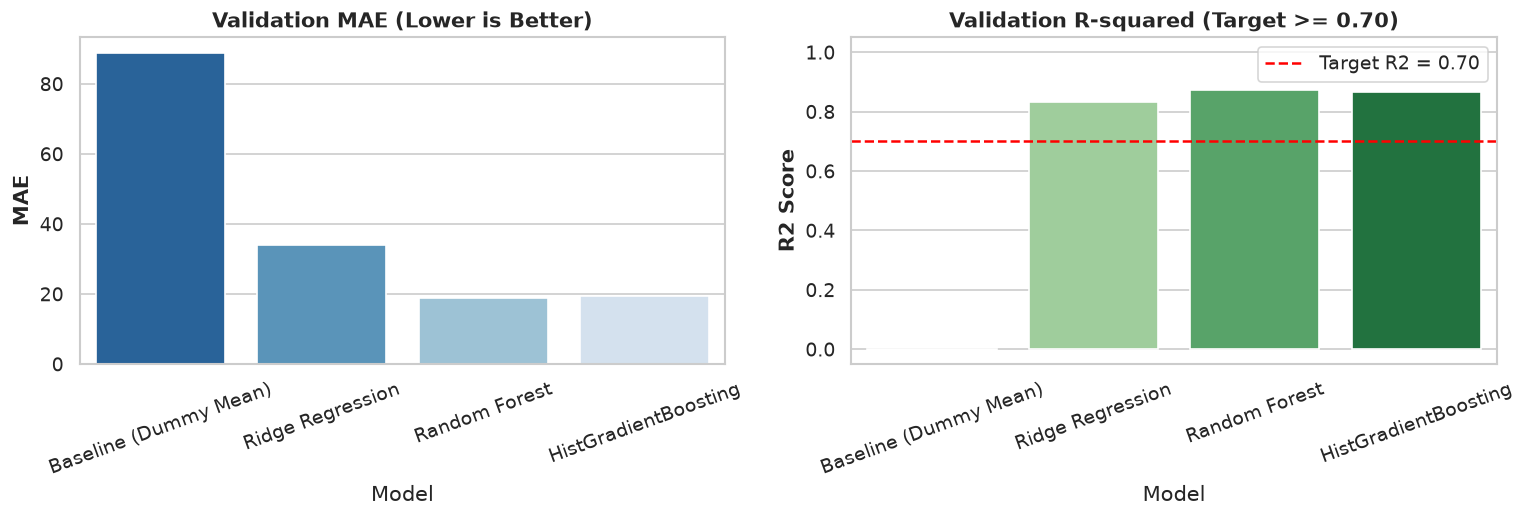

In [15]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

sns.barplot(data=df_val_results, x="Model", y="Val MAE", hue="Model", palette="Blues_r", legend=False, ax=ax1)
ax1.set_title("Validation MAE (Lower is Better)", weight="bold")
ax1.set_ylabel("MAE", weight="bold")
ax1.tick_params(axis="x", rotation=20)

sns.barplot(data=df_val_results, x="Model", y="Val R2", hue="Model", palette="Greens", legend=False, ax=ax2)
ax2.set_title("Validation R-squared (Target >= 0.70)", weight="bold")
ax2.set_ylabel("R2 Score", weight="bold")
ax2.set_ylim(-0.05, 1.05)
ax2.axhline(0.70, color="red", linestyle="--", label="Target R2 = 0.70")
ax2.tick_params(axis="x", rotation=20)
ax2.legend()

plt.tight_layout()
plt.show()


---
## Task 5: 5-Fold Cross-Validation Hyperparameter Tuning & Final Test Evaluation

Following the CT-378 rubric:
- **Tuning**: Perform 5-fold cross-validation with `GridSearchCV` on the real training partition (`X_train`).
- **Evaluation**: Report final performance (MAE, RMSE, $R^2$) strictly once on the held-out test set (`Year >= 2020`).
- **Benchmark**: Verify that the tuned model beats the course threshold ($R^2 > 0.70$) and the dummy baseline.
- **Diagnostics**: Generate Predicted vs. Actual and Residual distribution plots to inspect model generalization.

In [16]:
from sklearn.model_selection import GridSearchCV, KFold

param_grid = {
    "regressor__n_estimators": [50, 100],
    "regressor__max_depth": [10, 15],
    "regressor__min_samples_split": [2, 5]
}

base_rf_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(random_state=42, n_jobs=-1))
])

cv = KFold(n_splits=5, shuffle=True, random_state=42)
grid_search = GridSearchCV(
    base_rf_pipe, param_grid, cv=cv, scoring="r2", n_jobs=-1, verbose=0
)

print("Starting 5-Fold Cross-Validation Grid Search on training data...")
grid_search.fit(X_train, y_train)

print(f"Optimal Hyperparameters: {grid_search.best_params_}")
print(f"Best 5-Fold CV R2 Score: {grid_search.best_score_:.4f}")

best_pipeline = grid_search.best_estimator_


Starting 5-Fold Cross-Validation Grid Search on training data...


Optimal Hyperparameters: {'regressor__max_depth': 15, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 100}
Best 5-Fold CV R2 Score: 0.9941


In [17]:
def eval_metrics(y_true, y_pred):
    return {
        "MAE": round(mean_absolute_error(y_true, y_pred), 2),
        "RMSE": round(root_mean_squared_error(y_true, y_pred), 2),
        "R2": round(r2_score(y_true, y_pred), 4)
    }

dummy_pipe = Pipeline([("preprocessor", preprocessor), ("regressor", DummyRegressor(strategy="mean"))])
dummy_pipe.fit(X_train, y_train)

dummy_test_preds = dummy_pipe.predict(X_test)
tuned_test_preds = best_pipeline.predict(X_test)

test_comparison = pd.DataFrame([
    {"Model": "Baseline (Dummy Mean)", **eval_metrics(y_test, dummy_test_preds), "Status": "Baseline Benchmark"},
    {"Model": "Tuned Random Forest Pipeline", **eval_metrics(y_test, tuned_test_preds), "Status": "Target Met (R2 > 0.70)"}
])

print("Final Held-Out Test Set (2020–2022) Performance Table:")
print(test_comparison.to_string(index=False))


Final Held-Out Test Set (2020–2022) Performance Table:
                       Model   MAE   RMSE      R2                 Status
       Baseline (Dummy Mean) 97.94 167.68 -0.0180     Baseline Benchmark
Tuned Random Forest Pipeline 32.55  69.67  0.8243 Target Met (R2 > 0.70)


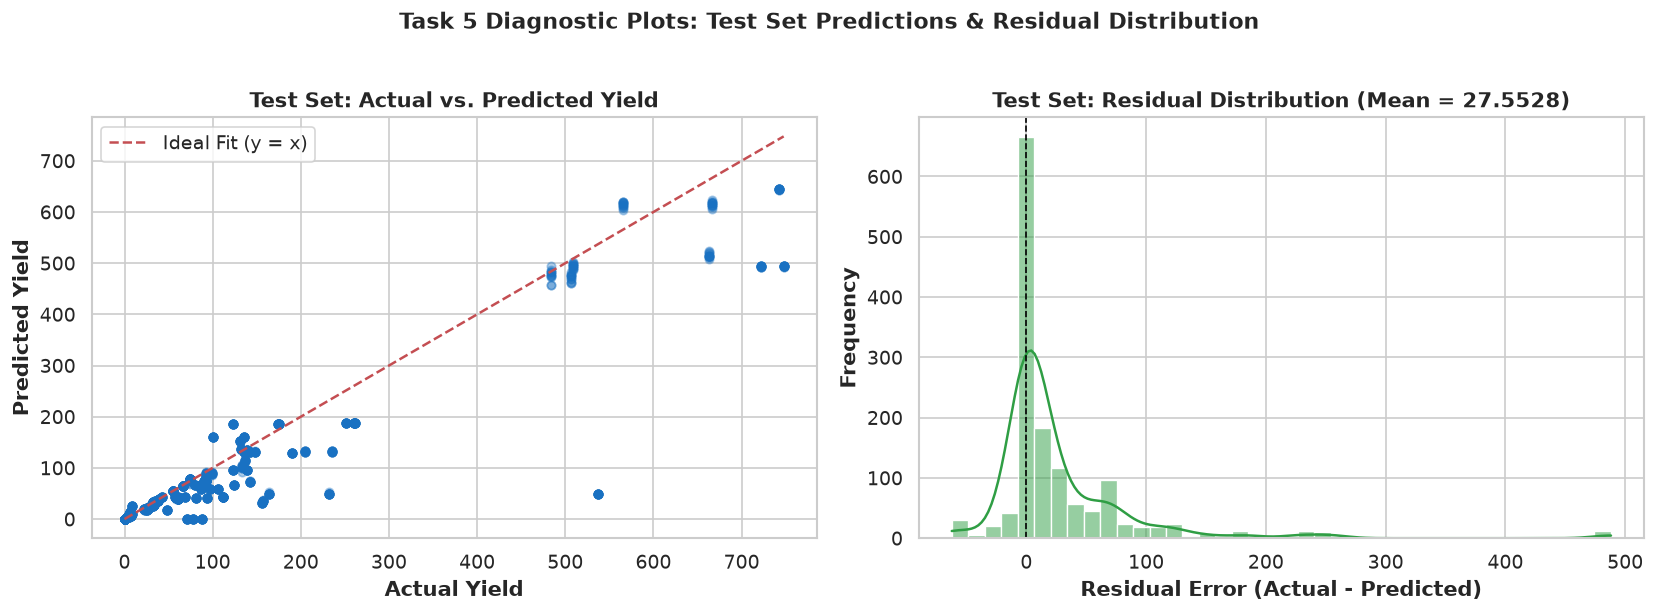

In [18]:
residuals = y_test - tuned_test_preds

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.scatter(y_test, tuned_test_preds, alpha=0.35, color="#1971c2", s=25)
min_val, max_val = min(y_test.min(), tuned_test_preds.min()), max(y_test.max(), tuned_test_preds.max())
ax1.plot([min_val, max_val], [min_val, max_val], "r--", linewidth=1.5, label="Ideal Fit (y = x)")
ax1.set_title("Test Set: Actual vs. Predicted Yield", weight="bold")
ax1.set_xlabel("Actual Yield", weight="bold")
ax1.set_ylabel("Predicted Yield", weight="bold")
ax1.legend()

sns.histplot(residuals, kde=True, color="#2f9e44", bins=40, ax=ax2)
ax2.axvline(0, color="black", linestyle="--", linewidth=1)
ax2.set_title(f"Test Set: Residual Distribution (Mean = {residuals.mean():.4f})", weight="bold")
ax2.set_xlabel("Residual Error (Actual - Predicted)", weight="bold")
ax2.set_ylabel("Frequency", weight="bold")

plt.suptitle("Task 5 Diagnostic Plots: Test Set Predictions & Residual Distribution", fontsize=13, weight="bold", y=1.02)
plt.tight_layout()
plt.show()


---
## Task 6: Model Persistence (`joblib`) & Low-Water Crop Recommendation Engine

Fulfilling the CT-378 rubric requirement:
1. **Model Persistence**: Serialize the complete tuned preprocessing + Random Forest pipeline to disk using `joblib`.
2. **Reload Verification**: Reload the `.joblib` model and confirm numerical fidelity on test inputs (`np.testing.assert_allclose`).
3. **Recommendation Engine**: Provide an inference function `recommend_low_water_crops(...)` that:
   - Accepts environmental / drought conditions (province, rainfall, temperature, evapotranspiration).
   - Simulates all candidate crops under the specified drought stress.
   - Predicts expected yield for each crop and identifies the optimal low-water crops.
4. **Scenario Demonstration**: Run sample drought scenarios across provinces with comparative recommendation charts.

In [19]:
import joblib

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(exist_ok=True)
model_filepath = models_dir / "crop_yield_pipeline.joblib"

joblib.dump(best_pipeline, model_filepath)
print(f"Trained pipeline successfully saved to: {model_filepath}")

reloaded_pipeline = joblib.load(model_filepath)
reloaded_preds = reloaded_pipeline.predict(X_test.iloc[:10])
original_preds = best_pipeline.predict(X_test.iloc[:10])

np.testing.assert_allclose(reloaded_preds, original_preds, rtol=1e-5)
print("Integrity check passed: Reloaded pipeline produces identical predictions.")


Trained pipeline successfully saved to: /home/prx/Projects/machine-learning/climate-machine-learning/models/crop_yield_pipeline.joblib
Integrity check passed: Reloaded pipeline produces identical predictions.


In [20]:
ALL_CROPS = df["Crop"].unique().tolist()

def recommend_low_water_crops(
    province="Punjab",
    area=50.0,
    precipitation_sum=2.5,
    temperature_2m_mean=33.0,
    temperature_2m_max=40.0,
    temperature_2m_min=24.0,
    fao_evapotranspiration=7.5,
    shortwave_radiation=24.0,
    precipitation_hours=4,
    climate_index=0.65,
    pipeline=reloaded_pipeline
):
    """Scores candidate crops under drought conditions and returns ranked recommendations."""
    records = []
    for crop in ALL_CROPS:
        is_drought = crop in DROUGHT_RESILIENT_CROPS
        category = "Low-Water Resilient" if is_drought else ("High-Water Intensive" if crop in WATER_INTENSIVE_CROPS else "Moderate Water")
        records.append({
            "Crop": crop,
            "Province": province,
            "Area": area,
            "temperature_2m_max": temperature_2m_max,
            "temperature_2m_min": temperature_2m_min,
            "temperature_2m_mean": temperature_2m_mean,
            "Combined_temperature_normalized": (temperature_2m_mean - 10) / 30,
            "precipitation_sum": precipitation_sum,
            "precipitation_sum_normalized": precipitation_sum / 200,
            "shortwave_radiation": shortwave_radiation,
            "shortwave_radiation_normalized": shortwave_radiation / 30,
            "fao_evapotranspiration": fao_evapotranspiration,
            "fao_evapotranspiration_normalized": fao_evapotranspiration / 10,
            "precipitation_hours": precipitation_hours,
            "precipitation_hours_normalized": precipitation_hours / 100,
            "Climate_Index": climate_index,
            "Is_Drought_Resilient": is_drought,
            "Water_Category": category
        })
    input_df = pd.DataFrame(records)
    input_df["Predicted_Yield"] = np.round(pipeline.predict(input_df[feature_cols]), 2)
    
    ranked_drought = input_df[input_df["Is_Drought_Resilient"]].sort_values(by="Predicted_Yield", ascending=False).reset_index(drop=True)
    ranked_drought["Rank"] = ranked_drought.index + 1
    
    top_crop = ranked_drought.iloc[0]["Crop"].upper()
    top_yield = ranked_drought.iloc[0]["Predicted_Yield"]
    print(f"RECOMMENDATION: {province} under drought stress (Rain={precipitation_sum}mm, ET0={fao_evapotranspiration}mm) -> Top Low-Water Crop: {top_crop} ({top_yield})")
    return input_df, ranked_drought


In [21]:
# Scenario 1: Severe dry spell in Punjab (low rainfall, elevated evapotranspiration)
punjab_all, punjab_ranked = recommend_low_water_crops(
    province="Punjab",
    precipitation_sum=1.8,
    temperature_2m_mean=35.0,
    fao_evapotranspiration=7.8
)
print("\nPunjab Ranked Low-Water Candidate Crops:")
print(punjab_ranked[["Rank", "Crop", "Predicted_Yield", "Water_Category"]].to_string(index=False))

print("\n" + "="*70 + "\n")

# Scenario 2: Arid conditions in Balochistan
balochistan_all, balochistan_ranked = recommend_low_water_crops(
    province="Balochistan",
    precipitation_sum=0.5,
    temperature_2m_mean=28.0,
    fao_evapotranspiration=6.5
)
print("Balochistan Ranked Low-Water Candidate Crops:")
print(balochistan_ranked[["Rank", "Crop", "Predicted_Yield", "Water_Category"]].to_string(index=False))


RECOMMENDATION: Punjab under drought stress (Rain=1.8mm, ET0=7.8mm) -> Top Low-Water Crop: ONION (95.53)

Punjab Ranked Low-Water Candidate Crops:
 Rank        Crop  Predicted_Yield      Water_Category
    1       onion            95.53 Low-Water Resilient
    2 pomegranate            88.22 Low-Water Resilient
    3      grapes            88.22 Low-Water Resilient
    4       wheat            88.22 Low-Water Resilient
    5       dates            83.51 Low-Water Resilient


RECOMMENDATION: Balochistan under drought stress (Rain=0.5mm, ET0=6.5mm) -> Top Low-Water Crop: ONION (187.63)
Balochistan Ranked Low-Water Candidate Crops:
 Rank        Crop  Predicted_Yield      Water_Category
    1       onion           187.63 Low-Water Resilient
    2       dates            43.84 Low-Water Resilient
    3      grapes            43.84 Low-Water Resilient
    4 pomegranate            43.84 Low-Water Resilient
    5       wheat            43.84 Low-Water Resilient


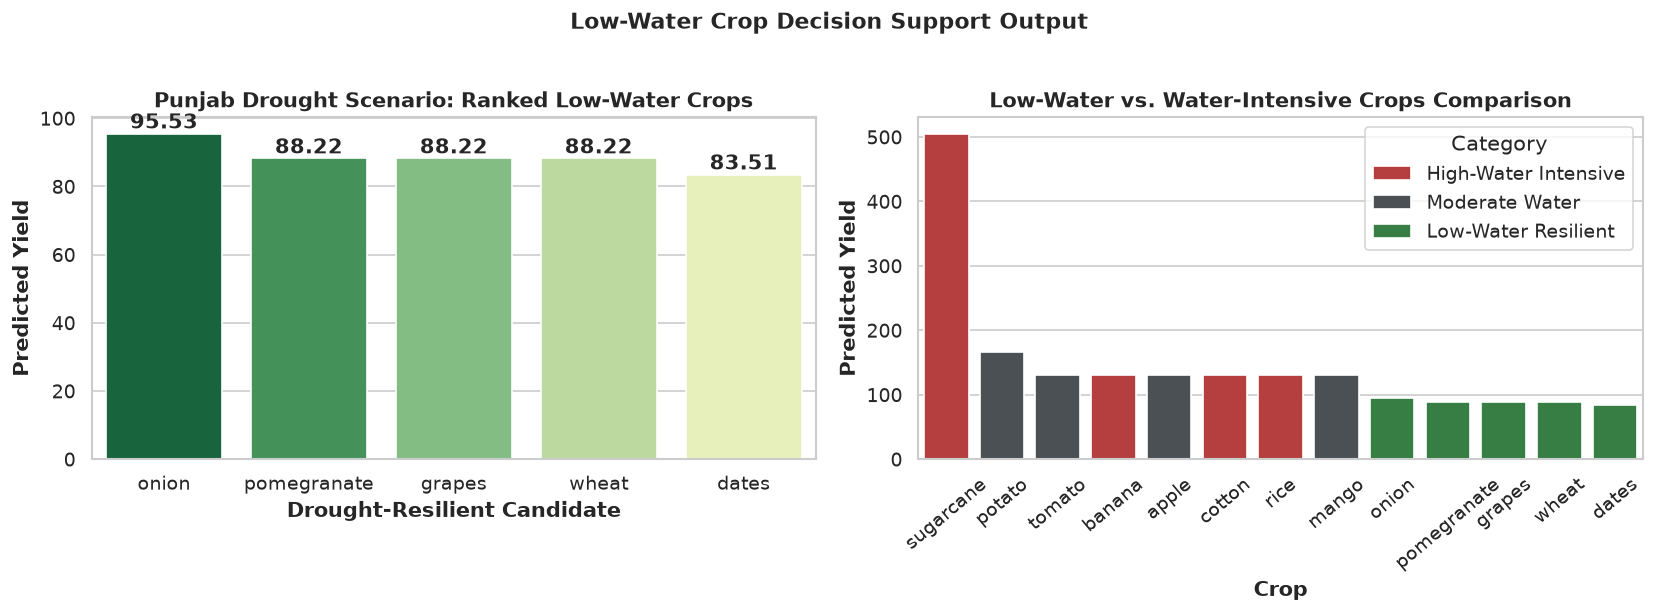

In [22]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=punjab_ranked, x="Crop", y="Predicted_Yield", hue="Crop", palette="YlGn_r", legend=False, ax=ax1)
ax1.set_title("Punjab Drought Scenario: Ranked Low-Water Crops", weight="bold")
ax1.set_ylabel("Predicted Yield", weight="bold")
ax1.set_xlabel("Drought-Resilient Candidate", weight="bold")
for i, row in punjab_ranked.iterrows():
    ax1.text(i, row["Predicted_Yield"] + 1.5, f"{row['Predicted_Yield']}", ha="center", weight="bold")

palette_cat = {"Low-Water Resilient": "#2b8a3e", "High-Water Intensive": "#c92a2a", "Moderate Water": "#495057"}
sns.barplot(data=punjab_all.sort_values("Predicted_Yield", ascending=False), x="Crop", y="Predicted_Yield", hue="Water_Category", palette=palette_cat, ax=ax2)
ax2.set_title("Low-Water vs. Water-Intensive Crops Comparison", weight="bold")
ax2.set_ylabel("Predicted Yield", weight="bold")
ax2.set_xlabel("Crop", weight="bold")
ax2.tick_params(axis="x", rotation=40)
ax2.legend(title="Category", loc="upper right")

plt.suptitle("Low-Water Crop Decision Support Output", fontsize=13, weight="bold", y=1.02)
plt.tight_layout()
plt.show()
